# Credit Scoring — Home Credit Default Risk

## О проекте

Учебный проект по бинарной классификации в рамках освоения логистической регрессии.
Цель — построить модель кредитного скоринга, предсказывающую вероятность дефолта
заёмщика по данным заявки, и научиться интерпретировать её результаты
(коэффициенты, odds ratio) в терминах, понятных бизнесу.

Структура проекта повторяет подход из предыдущего проекта
[hot-jupiter-detector](https://github.com/DigitalOcean78/hot-jupiter-detector):
одна тетрадка, лаконичное оформление, акцент на интерпретации модели.

## Постановка задачи

**Тип задачи:** бинарная классификация.

**Целевая переменная:** `TARGET`
- `0` — клиент вернул кредит в срок (good)
- `1` — у клиента возникли трудности с платежами (default)

**Что предсказываем:** вероятность дефолта `P(TARGET = 1 | X)` по признакам заявки.

**Метрики качества:**
- ROC-AUC и Gini (= 2·AUC − 1) — основная метрика в скоринге;
- KS-statistic — стандарт индустрии;
- PR-AUC — информативна при дисбалансе классов;
- Brier score — качество калибровки вероятностей.

**Особенности задачи:**
- сильный дисбаланс классов (дефолтов ~8%);
- стоимость ошибок несимметрична: пропущенный дефолт (FN) дороже ложной тревоги (FP);
- в реальном скоринге требуется интерпретируемость модели.

## Описание данных

**Источник:** [Home Credit Default Risk](https://www.kaggle.com/c/home-credit-default-risk), файл `application_train.csv`.

**Размер:** 307 511 строк × 122 признака. Одна строка — один клиент.

**Целевая переменная `TARGET`:**
- `0` — кредит возвращён (282 686, 91.93%);
- `1` — дефолт (24 825, 8.07%);
- дисбаланс ~11.4 : 1.

**Типы признаков:** 65 `float64`, 41 `int64`, 16 `object`
(категориальные — под One-Hot).

**Группы признаков:**
- `SK_ID_CURR` — ID клиента (в модель не идёт), `TARGET` — цель;
- демография: `CODE_GENDER`, `DAYS_BIRTH`, `NAME_EDUCATION_TYPE`, `NAME_FAMILY_STATUS` и др.;
- доход и занятость: `AMT_INCOME_TOTAL`, `NAME_INCOME_TYPE`, `DAYS_EMPLOYED`, `OCCUPATION_TYPE`, `ORGANIZATION_TYPE`;
- кредит: `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`, `NAME_CONTRACT_TYPE`;
- внешние скоринговые баллы: `EXT_SOURCE_1/2/3` (сильнейшие признаки, у `EXT_SOURCE_1` ~56% пропусков);
- блок housing (~47 колонок `*_AVG/_MODE/_MEDI`) — характеристики жилья, >50% пропусков;
- флаги документов/контактов и `DAYS_*` — интервалы в днях до заявки.

**Известные аномалии:**
- `DAYS_EMPLOYED = 365243` — маркер «не работает»;
- `CODE_GENDER = 'XNA'` — единичные записи;
- пропуски в housing структурные (заполнен либо весь блок, либо ничего);
- высокая кардинальность `ORGANIZATION_TYPE` (~58) и `OCCUPATION_TYPE` (~31).

## 2. Imports & setup

In [15]:
# --- Core ---
import pandas as pd
import numpy as np

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Modeling ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report,
    brier_score_loss
)

# --- Stats ---
from scipy.stats import ks_2samp

# --- Settings ---
RANDOM_STATE = 42
pd.set_option('display.max_columns', 200)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print("Imports OK")

Imports OK


## 3. Load data & first look

In [2]:
# Загрузка
df = pd.read_csv('../data/application_train.csv')

print(f"Shape: {df.shape}")
print(f"Rows: {df.shape[0]:,}, Columns: {df.shape[1]}")

# Целевая переменная
print("\nTARGET distribution:")
print(df['TARGET'].value_counts())
print(f"\nDefault rate: {df['TARGET'].mean():.4f} ({df['TARGET'].mean()*100:.2f}%)")

# Типы признаков
print("\nDtypes summary:")
print(df.dtypes.value_counts())

# Первые строки
df.head(3)

Shape: (307511, 122)
Rows: 307,511, Columns: 122

TARGET distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Default rate: 0.0807 (8.07%)

Dtypes summary:
float64    65
int64      41
object     16
Name: count, dtype: int64


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0000,406597.5000,24700.5000,351000.0000,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,-3648.0000,-2120,NaN,1,1,0,1,1,0,Laborers,1.0000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.0830,0.2629,0.1394,0.0247,0.0369,0.9722,0.6192,0.0143,0.0000,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.0220,0.0198,0.0000,0.0000,0.0250,0.0369,0.9722,0.6243,0.0144,0.0000,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.0000,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0000,2.0000,2.0000,2.0000,-1134.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1,100003,0,Cash loans,F,N,N,0,270000.0000,1293502.5000,35698.5000,1129500.0000,Family,State servant,Higher education,Married,House / apartment,0.0035,-16765,-1188,-1186.0000,-291,NaN,1,1,0,1,1,0,Core staff,2.0000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.3113,0.6222,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.0800,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.0790,0.0554,0.0000,0.0000,0.0968,0.0529,0.9851,0.7987,0.0608,0.0800,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.0100,reg oper account,block of flats,0.0714,Block,No,1.0000,0.0000,1.0000,0.0000,-828.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,100004,0,Revolving loans,M,Y,Y,0,67500.0000,135000.0000,6750.0000,135000.0000,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0100,-19046,-225,-4260.0000,-2531,26.0000,1,1,1,1,1,0,Laborers,1.0000,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.5559,0.

### Вывод

Данные загружены корректно: **307 511 строк × 122 признака** — совпадает с ожидаемым размером `application_train.csv`.

Целевая переменная `TARGET` сильно разбалансирована: **24 825 дефолтов (8.07%)** против 282 686 возвратов (91.93%), соотношение ~11.4 : 1. Это означает, что:
- `accuracy` как метрика непригодна (константное предсказание «0» даёт 91.93%);
- будем использовать **ROC-AUC, Gini, KS, PR-AUC** и `class_weight='balanced'` в модели.

По типам признаков: **65 `float64`, 41 `int64`, 16 `object`**. Категориальные 16 колонок — кандидаты на One-Hot Encoding; отметим высококардинальные (`ORGANIZATION_TYPE` ~58, `OCCUPATION_TYPE` ~31) как потенциальную проблему размерности.

При первичном осмотре `head(3)` выявлены аномалии, которые нужно обработать на этапе предобработки:
- `DAYS_EMPLOYED = 365243` — маркер «не работает»;
- `CODE_GENDER = 'XNA'` — единичные записи;
- блок housing (`*_AVG/_MODE/_MEDI`) с большим числом пропусков;
- `EXT_SOURCE_1` частично отсутствует, но остаётся ценным признаком.

Переходим к EDA: анализ пропусков и распределений ключевых признаков.

## 4. EDA

### 4.1 Пропуски

In [3]:
# --- Пропуски ---
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'n_missing': missing,
    'pct_missing': missing_pct
})

print(f"Колонок с пропусками: {len(missing_df)} из {df.shape[1]}")
print(f"Колонок с >50% пропусков: {(missing_pct > 50).sum()}")
print(f"Колонок с >30% пропусков: {(missing_pct > 30).sum()}")

print("\nТоп-20 по доле пропусков:")
missing_df.head(20)

Колонок с пропусками: 67 из 122
Колонок с >50% пропусков: 41
Колонок с >30% пропусков: 50

Топ-20 по доле пропусков:


,n_missing,pct_missing
COMMONAREA_MEDI,214865,69.8700
COMMONAREA_MODE,214865,69.8700
COMMONAREA_AVG,214865,69.8700
NONLIVINGAPARTMENTS_MODE,213514,69.4300
NONLIVINGAPARTMENTS_MEDI,213514,69.4300
NONLIVINGAPARTMENTS_AVG,213514,69.4300
FONDKAPREMONT_MODE,210295,68.3900
LIVINGAPARTMENTS_AVG,210199,68.3500
LIVINGAPARTMENTS_MEDI,210199,68.3500
LIVINGAPARTMENTS_MODE,210199,68.3500


### 4.2 Карта пропусков

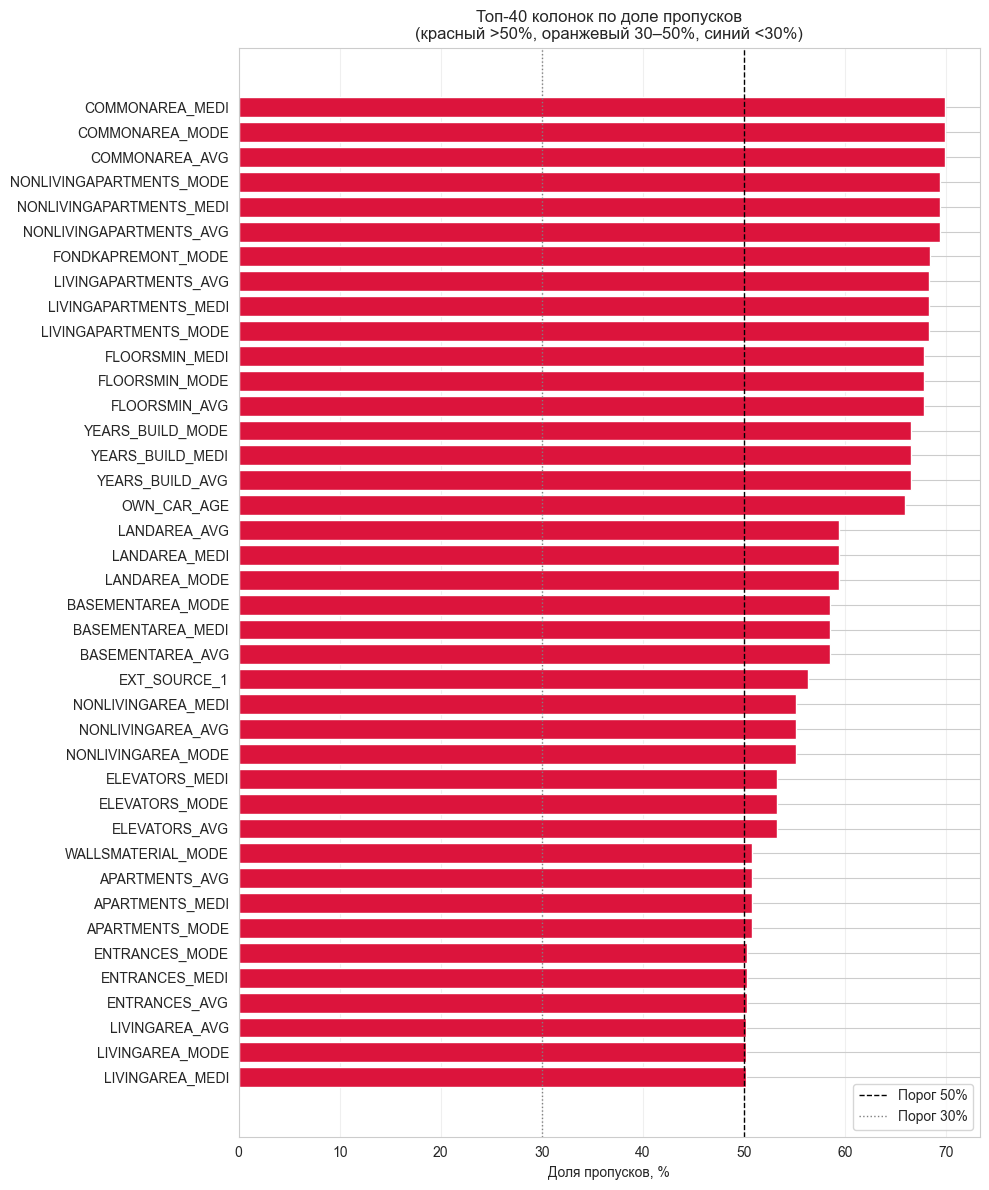

In [4]:
# Берём все колонки с пропусками, но для читаемости — топ-40
top_missing = missing_df.head(40).copy()
top_missing['feature'] = top_missing.index

fig, ax = plt.subplots(figsize=(10, 12))

# Цвет: >50% — красный, 30–50% — оранжевый, <30% — синий
colors = ['crimson' if x > 50 else 'orange' if x > 30 else 'steelblue'
          for x in top_missing['pct_missing']]

bars = ax.barh(top_missing['feature'], top_missing['pct_missing'], color=colors)
ax.invert_yaxis()  # самый большой пропуск — сверху
ax.axvline(50, color='black', linestyle='--', linewidth=1, label='Порог 50%')
ax.axvline(30, color='gray', linestyle=':', linewidth=1, label='Порог 30%')
ax.set_xlabel('Доля пропусков, %')
ax.set_title('Топ-40 колонок по доле пропусков\n(красный >50%, оранжевый 30–50%, синий <30%)')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# Колонки в диапазоне 30-50%
orange_cols = missing_df[(missing_df['pct_missing'] > 30) & (missing_df['pct_missing'] <= 50)]
print(f"Колонок в диапазоне 30-50%: {len(orange_cols)}")
orange_cols

Колонок в диапазоне 30-50%: 9


,n_missing,pct_missing
FLOORSMAX_AVG,153020,49.7600
FLOORSMAX_MEDI,153020,49.7600
FLOORSMAX_MODE,153020,49.7600
YEARS_BEGINEXPLUATATION_MODE,150007,48.7800
YEARS_BEGINEXPLUATATION_MEDI,150007,48.7800
YEARS_BEGINEXPLUATATION_AVG,150007,48.7800
TOTALAREA_MODE,148431,48.2700
EMERGENCYSTATE_MODE,145755,47.4000
OCCUPATION_TYPE,96391,31.3500


### Вывод по пропускам

Из 122 колонок 67 имеют пропуски. Распределение:
- **>50% (41 колонка)** — почти весь блок housing + `OWN_CAR_AGE` + `EXT_SOURCE_1`;
- **30–50% (9 колонок)** — оставшиеся housing-признаки + `OCCUPATION_TYPE`;
- **<30% (17 колонок)** — умеренные пропуски, импутируются без потерь.

Пропуски в housing **структурные**: у 47.4% клиентов блок отсутствует целиком, у 25.6% — заполнен полностью. Удалять такие строки нельзя, но колонки — можно.

**Решения для шага 5:**
- удалить **48 колонок**: 40 housing с >50% + 7 housing из диапазона 30–50% + `OWN_CAR_AGE`;
- `EXT_SOURCE_1` (56% пропусков) — **оставить**, заполнить медианой + флаг `EXT_SOURCE_1_isna`;
- `OCCUPATION_TYPE` (31.35%) — **оставить**, заполнить категорией `'Unknown'`;
- остальные колонки — медиана (числовые) / мода или `'Unknown'` (категориальные).

### 4.3 Числовые признаки vs TARGET

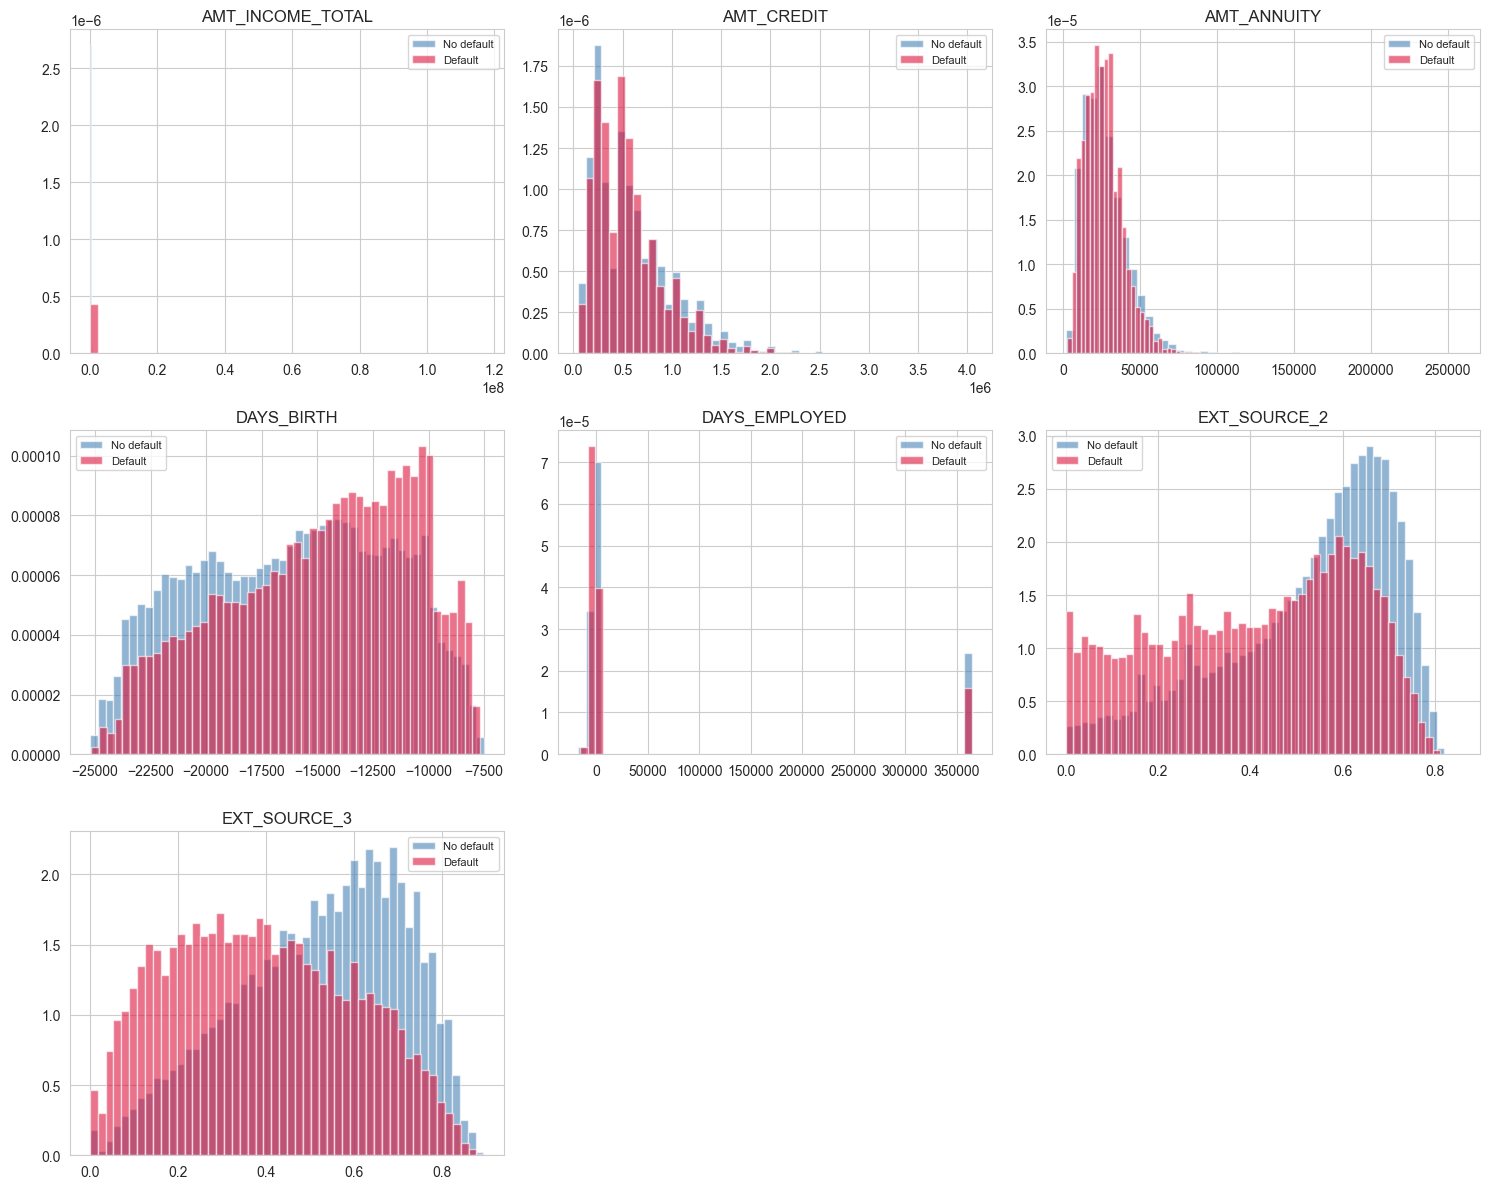

In [6]:
key_num_cols = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
                'DAYS_BIRTH', 'DAYS_EMPLOYED', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(key_num_cols):
    for target_val, label, color in [(0, 'No default', 'steelblue'),
                                     (1, 'Default', 'crimson')]:
        data = df.loc[df['TARGET'] == target_val, col].dropna()
        axes[i].hist(data, bins=50, alpha=0.6, label=label, color=color, density=True)
    axes[i].set_title(col)
    axes[i].legend(fontsize=8)

for j in range(len(key_num_cols), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

### Вывод по числовым признакам

- **`EXT_SOURCE_2` и `EXT_SOURCE_3`** — сильнейшие признаки: распределения дефолтов и недефолтов четко смещены (низкий балл → высокий риск). На них будет опираться модель.
- **`DAYS_BIRTH`** — заметное разделение: молодые клиенты дефолтят чаще. Признак информативен (позже можно перевести в возраст в годах).
- **`DAYS_EMPLOYED`** — содержит аномалию `365243` (маркер «не работает»), дающую огромный пик. Требует замены на `NaN` + создания бинарного флага `IS_UNEMPLOYED`.
- **`AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`** — сильно скошены, распределения классов почти совпадают. Признаки слабые, но из-за разных масштабов обязательна стандартизация.

**Решения для шага 5:** масштабировать все числовые признаки (`StandardScaler`), обработать аномалию `DAYS_EMPLOYED`, создать флаг `IS_UNEMPLOYED`.

### 4.4 Категориальные признаки vs TARGET

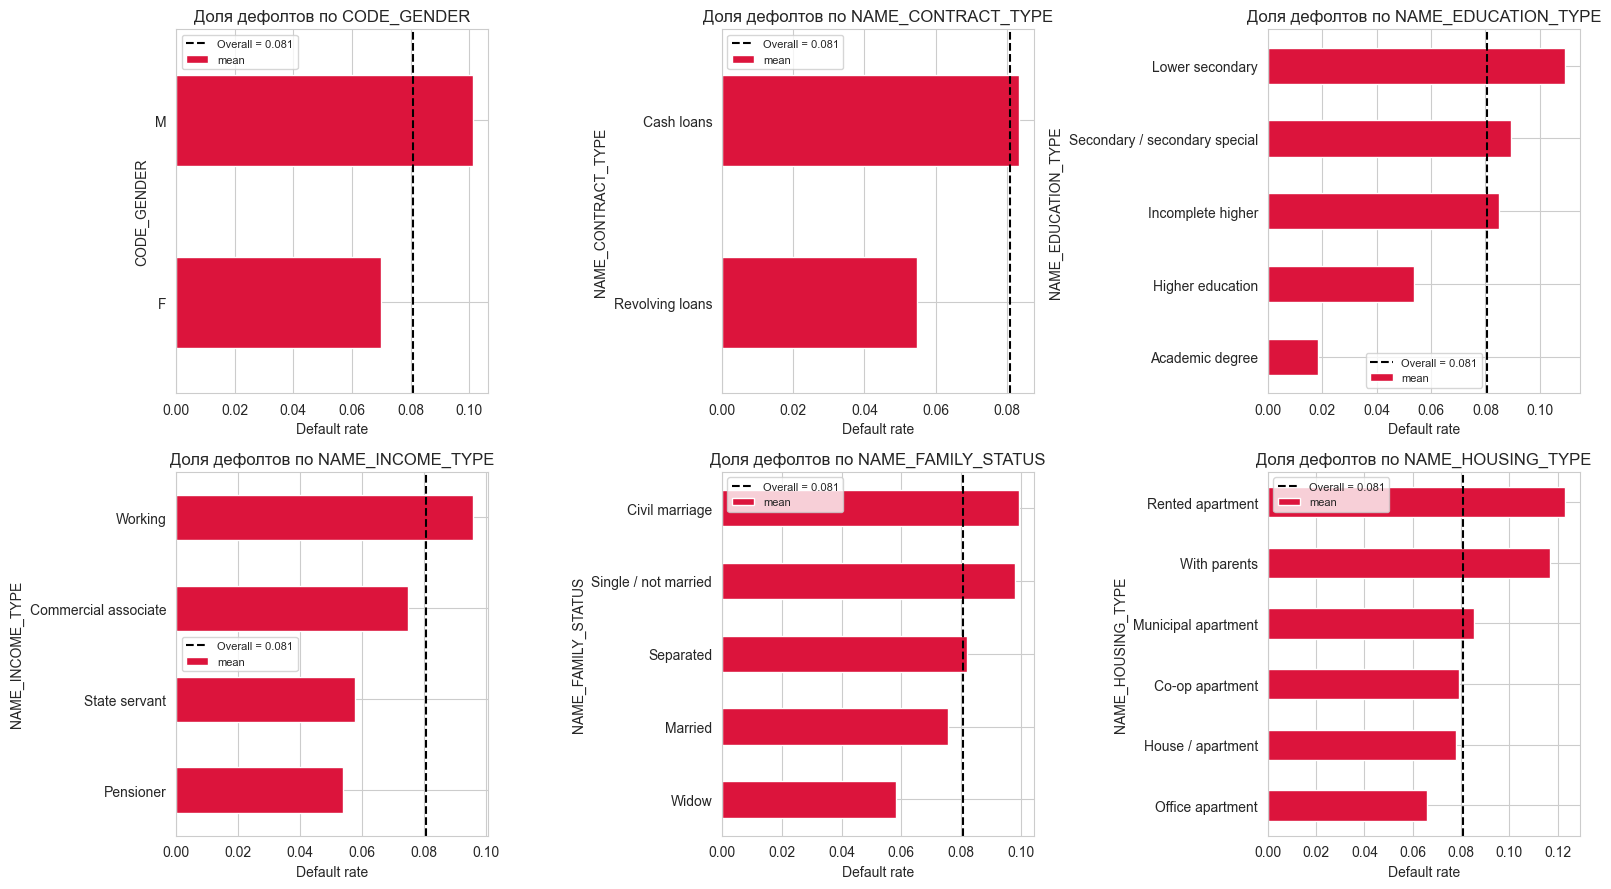

In [7]:
key_cat_cols = ['CODE_GENDER', 'NAME_CONTRACT_TYPE', 'NAME_EDUCATION_TYPE',
                'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(key_cat_cols):
    default_rate = df.groupby(col)['TARGET'].agg(['mean', 'count'])
    default_rate = default_rate[default_rate['count'] > 100]
    default_rate['mean'].sort_values().plot(
        kind='barh', ax=axes[i], color='crimson'
    )
    axes[i].set_title(f'Доля дефолтов по {col}')
    axes[i].set_xlabel('Default rate')
    axes[i].axvline(df['TARGET'].mean(), color='black', linestyle='--',
                    label=f'Overall = {df["TARGET"].mean():.3f}')
    axes[i].legend(fontsize=8)

for j in range(len(key_cat_cols), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

### Вывод по категориальным признакам

Все 6 категориальных признаков показали заметную связь с целевой переменной и будут полезны для модели:
- **`NAME_EDUCATION_TYPE`** — сильнейший признак: разброс default rate от ~2% (Academic degree) до ~11% (Lower secondary).
- **`NAME_INCOME_TYPE`** — высокий риск у Working, низкий у Pensioner.
- **`CODE_GENDER`** — мужчины дефолтят чаще женщин (~10% vs ~7%).
- **`NAME_FAMILY_STATUS`** — Civil marriage и Single рискуют больше, чем Married и Widow.
- **`NAME_CONTRACT_TYPE`** — Cash loans рискованнее Revolving loans.
- **`NAME_HOUSING_TYPE`** — Rented apartment и With parents имеют повышенный риск.

**Решение для шага 5:** применять One-Hot Encoding ко всем 16 `object`-колонкам. Для `OCCUPATION_TYPE` (31% пропусков) отдельная категория `'Unknown'` сохранит сигнал.

### Вывод по EDA

1. **Пропуски:** 67 колонок имеют пропуски, 41 из них — >50% (блок housing). Пропуски структурные: у 47.4% клиентов блок отсутствует целиком, что делает импутацию неэффективной. 
2. **Числовые признаки:** `EXT_SOURCE_2/3` и `DAYS_BIRTH` показали отличное разделение классов. Признаки `AMT_*` слабые и требуют масштабирования. В `DAYS_EMPLOYED` найдена аномалия `365243`, требующая замены и создания флага.
3. **Категориальные признаки:** все 6 рассмотренных признаков информативны. Наибольший разброс в default rate дают `NAME_EDUCATION_TYPE` (2–11%) и `NAME_INCOME_TYPE`.

**План на шаг 5 (Preprocessing):**
- Удалить ~48 ненужных колонок (housing >30% пропусков + `OWN_CAR_AGE`).
- Обработать аномалию `DAYS_EMPLOYED` + создать флаг `IS_UNEMPLOYED`.
- Импутировать оставшиеся пропуски (медиана для чисел, `'Unknown'` для категорий).
- Закодировать 16 категориальных колонок через One-Hot.
- Масштабировать признаки через `StandardScaler`.

## 5. Preprocessing

### 5.1 Очистка данных и обработка аномалий

In [8]:
# Копируем исходный датасет для работы
data = df.copy()

# 1. Аномалия в DAYS_EMPLOYED (маркер "не работает")
# Создаем флаг перед заменой
data['IS_UNEMPLOYED'] = (data['DAYS_EMPLOYED'] == 365243).astype(int)
data['DAYS_EMPLOYED'] = data['DAYS_EMPLOYED'].replace(365243, np.nan)

# 2. Удаляем ID-шник и целевую переменную (отделяем X и y)
y = data['TARGET']
X = data.drop(columns=['TARGET', 'SK_ID_CURR'])

# 3. Удаляем колонки с >50% пропусков (из EDA), КРОМЕ EXT_SOURCE_1
cols_50_plus = missing_df[missing_df['pct_missing'] > 50].index.tolist()
cols_to_drop = [c for c in cols_50_plus if c != 'EXT_SOURCE_1']

# 4. Удаляем оставшиеся housing из диапазона 30-50%
housing_orange_to_drop = [
    'FLOORSMAX_AVG', 'FLOORSMAX_MEDI', 'FLOORSMAX_MODE',
    'YEARS_BEGINEXPLUATATION_MODE', 'YEARS_BEGINEXPLUATATION_MEDI',
    'YEARS_BEGINEXPLUATATION_AVG', 'TOTALAREA_MODE', 'EMERGENCYSTATE_MODE'
]
cols_to_drop.extend(housing_orange_to_drop)

# Удаляем
X = X.drop(columns=cols_to_drop, errors='ignore')

print(f"Удалено колонок: {len(cols_to_drop)}")
print(f"Осталось колонок: {X.shape[1]}")
print(f"Осталось строк: {X.shape[0]}")

Удалено колонок: 48
Осталось колонок: 73
Осталось строк: 307511


### Вывод по очистке данных

- Из 122 исходных колонок удалено 48 «мусорных» (housing-блок с >30% пропусков + `OWN_CAR_AGE`), осталось **73 признака**.
- Строки не удалялись: сохранены все **307 511 клиентов**, включая 47.4% без данных о жилье.
- Аномалия `DAYS_EMPLOYED = 365243` заменена на `NaN` (для последующей импутации), создан бинарный флаг **`IS_UNEMPLOYED`**, который сохранит информацию о статусе «не работает».
- `SK_ID_CURR` и `TARGET` отделены: `X` (признаки) и `y` (цель).

### 5.2 Импутация пропусков

In [9]:
# 1. Разделяем на числовые и категориальные
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

print(f"Числовых колонок: {len(num_cols)}")
print(f"Категориальных колонок: {len(cat_cols)}")

# 2. Числовые заполняем медианой
# Используем SimpleImputer для аккуратности
num_imputer = SimpleImputer(strategy='median')
X[num_cols] = num_imputer.fit_transform(X[num_cols])

# 3. Категориальные заполняем 'Unknown'
cat_imputer = SimpleImputer(strategy='constant', fill_value='Unknown')
X[cat_cols] = cat_imputer.fit_transform(X[cat_cols])

# 4. Проверка: остались ли пропуски?
remaining_missing = X.isnull().sum().sum()
print(f"\nОсталось пропусков после импутации: {remaining_missing}")

if remaining_missing == 0:
    print("✅ Все пропуски заполнены")

Числовых колонок: 61
Категориальных колонок: 12

Осталось пропусков после импутации: 0
✅ Все пропуски заполнены


### Вывод по импутации

- Все пропуски заполнены: **0 NaN** в датасете.
- **61 числовая колонка** — заполнены медианой (устойчиво к выбросам в `AMT_*`).
- **12 категориальных колонок** — заполнены значением `'Unknown'`, что сохраняет сигнал «данных нет» (особенно для `OCCUPATION_TYPE` с 31% пропусков).
- Данные готовы к кодированию и масштабированию.

### 5.3 One-Hot Encoding и train/test split

In [10]:
# 1. One-Hot Encoding
# drop_first=True убирает первую категорию каждого признака (защита от мультиколлинеарности)
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

print(f"Колонок до One-Hot: {X.shape[1]}")
print(f"Колонок после One-Hot: {X_encoded.shape[1]}")

# 2. Train/test split
# stratify=y гарантирует одинаковую долю дефолтов в train и test
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"\nTrain: {X_train.shape[0]:,} строк, дефолтов: {y_train.mean()*100:.2f}%")
print(f"Test:  {X_test.shape[0]:,} строк, дефолтов: {y_test.mean()*100:.2f}%")

# 3. Масштабирование (fit на train, transform на обоих!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nScaler fitted on train, применён к test.")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape:  {X_test_scaled.shape}")

Колонок до One-Hot: 73
Колонок после One-Hot: 175

Train: 246,008 строк, дефолтов: 8.07%
Test:  61,503 строк, дефолтов: 8.07%

Scaler fitted on train, применён к test.
X_train_scaled shape: (246008, 175)
X_test_scaled shape:  (61503, 175)


### Вывод по кодированию и разделению

- **One-Hot Encoding** превратил 12 категориальных признаков в 102 бинарные колонки (всего 175 признаков). `drop_first=True` защищает от мультиколлинеарности.
- **Train/test split** (80/20) со стратификацией сохранил долю дефолтов **8.07%** в обеих выборках (246k и 61.5k строк). Это обеспечит корректную оценку модели на тесте.
- **`StandardScaler`** обучен только на train и применён к test — утечки данных нет. Признаки готовы к подаче в LogReg.

### Итоговый вывод по предобработке

- **Очистка:** удалено 48 «мусорных» колонок (housing + `OWN_CAR_AGE`), обработана аномалия `DAYS_EMPLOYED` с созданием флага `IS_UNEMPLOYED`. Осталось 73 признака, строки сохранены (307 511).
- **Импутация:** все пропуски заполнены (0 NaN) — медианой для 61 числовой колонки, категорией `'Unknown'` для 12 категориальных.
- **Кодирование:** One-Hot Encoding превратил 12 `object`-колонок в 102 бинарные, итого **175 признаков**.
- **Разделение:** train/test (80/20) со стратификацией — по 8.07% дефолтов в обеих выборках (246k и 61.5k строк).
- **Масштабирование:** `StandardScaler` обучен только на train и применён к test — утечки данных нет.

Данные полностью готовы к обучению модели. Дисбаланс классов сохранён, признаки стандартизированы, мультиколлинеарность категориальных признаков устранена.

## 6. Baseline model (Logistic Regression)

In [11]:
# 1. Обучение модели
model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=RANDOM_STATE
)
model.fit(X_train_scaled, y_train)

print("Модель обучена.")

# 2. Предсказания (вероятности и классы)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
y_pred = model.predict(X_test_scaled)

auc = roc_auc_score(y_test, y_pred_proba)
gini = 2 * auc - 1
pr_auc = average_precision_score(y_test, y_pred_proba)
brier = brier_score_loss(y_test, y_pred_proba)

# KS-statistic: максимальное расстояние между CDF классов
ks_stat = ks_2samp(y_pred_proba[y_test == 0], y_pred_proba[y_test == 1]).statistic

print(f"\n--- Метрики на test ---")
print(f"ROC-AUC:  {auc:.4f}")
print(f"Gini:     {gini:.4f}")
print(f"PR-AUC:   {pr_auc:.4f}")
print(f"KS:       {ks_stat:.4f}")
print(f"Brier:    {brier:.4f}")

# 4. Матрица ошибок
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=3))

Модель обучена.

--- Метрики на test ---
ROC-AUC:  0.7485
Gini:     0.4971
PR-AUC:   0.2288
KS:       0.3689
Brier:    0.2026

Confusion Matrix:
[[39025 17513]
 [ 1610  3355]]

Classification Report:
              precision    recall  f1-score   support

           0      0.960     0.690     0.803     56538
           1      0.161     0.676     0.260      4965

    accuracy                          0.689     61503
   macro avg      0.561     0.683     0.531     61503
weighted avg      0.896     0.689     0.759     61503



### Вывод по baseline-модели

Baseline LogReg с `class_weight='balanced'` показал **ROC-AUC = 0.7485**, **Gini = 0.4971**, **KS = 0.3689** — все метрики в ожидаемом диапазоне для Home Credit.

- **Recall для дефолтов = 0.676** — модель ловит 67.6% дефолтов, что критично для скоринга (FN дороже FP).
- **Precision для дефолтов = 0.161** — низкая, но это плата за `class_weight='balanced'`: модель «перестраховывается» и даёт много ложных тревог (17.5k FP).
- **Brier = 0.2026** — высоковато, вероятности плохо откалиброваны (типично для взвешенных моделей). Кандидат на калибровку в шаге 8.

Модель работает корректно как для учебного baseline. Есть куда улучшать: интерпретация, калибровка вероятностей, тюнинг порога, scorecard.

## 7. Model interpretation

Топ-20 признаков по |coef|:


,feature,coef,odds_ratio
4,AMT_GOODS_PRICE,-0.9789,0.3757
2,AMT_CREDIT,0.9195,2.5080
28,EXT_SOURCE_3,-0.4772,0.6205
27,EXT_SOURCE_2,-0.3909,0.6764
26,EXT_SOURCE_1,-0.1809,0.8346
18,REGION_RATING_CLIENT_W_CITY,0.1697,1.1849
62,CODE_GENDER_M,0.1524,1.1646
83,NAME_EDUCATION_TYPE_Secondary / secondary special,0.1515,1.1636
7,DAYS_EMPLOYED,0.1415,1.1520
35,FLAG_DOCUMENT_3,0.1296,1.1383


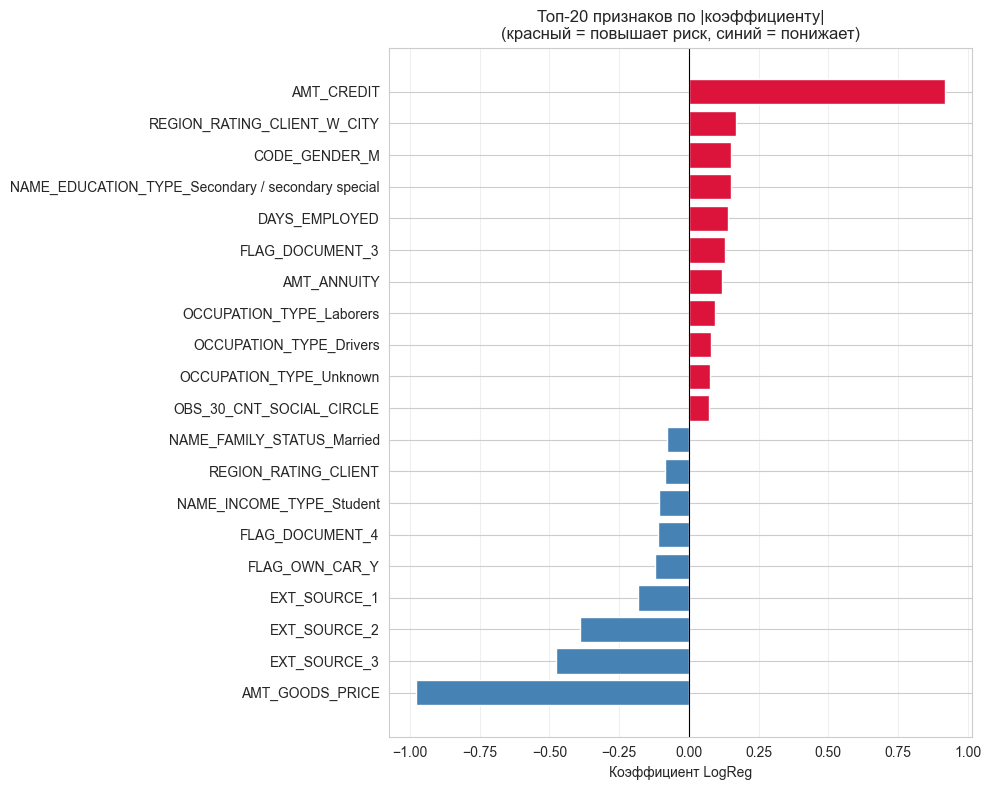

In [12]:
# 1. Достаём коэффициенты и сопоставляем с признаками
coefs = pd.DataFrame({
    'feature': X_train.columns,
    'coef': model.coef_[0]
})

# 2. Odds ratio = exp(coef)
coefs['odds_ratio'] = np.exp(coefs['coef'])

# 3. Сортируем по абсолютному значению коэффициента
coefs['abs_coef'] = coefs['coef'].abs()
coefs_sorted = coefs.sort_values('abs_coef', ascending=False)

# 4. Топ-20 самых важных признаков
print("Топ-20 признаков по |coef|:")
display(coefs_sorted.head(20)[['feature', 'coef', 'odds_ratio']])

# 5. Визуализация: топ-20 по коэффициенту
top20 = coefs_sorted.head(20).sort_values('coef')

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['crimson' if c > 0 else 'steelblue' for c in top20['coef']]
ax.barh(top20['feature'], top20['coef'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Коэффициент LogReg')
ax.set_title('Топ-20 признаков по |коэффициенту|\n(красный = повышает риск, синий = понижает)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### Вывод по интерпретации

Модель выявила логичные и объяснимые зависимости:

**Главные факторы риска (повышают шанс дефолта):**
- `AMT_CREDIT` (OR 2.51) — сумма кредита, доминирующий фактор;
- `REGION_RATING_CLIENT_W_CITY` — плохой регион = выше риск;
- `CODE_GENDER_M` (OR 1.16) — мужчины, совпадает с EDA;
- `NAME_EDUCATION_TYPE_Secondary` — среднее образование;
- `DAYS_EMPLOYED` — малый стаж работы.

**Главные защитные факторы (понижают риск):**
- `AMT_GOODS_PRICE` (OR 0.38) — дорогой товар/залог;
- `EXT_SOURCE_1/2/3` — все три внешних балла, ровно как предсказывал EDA;
- `FLAG_OWN_CAR_Y` — наличие машины;
- `NAME_FAMILY_STATUS_Married` — семейное положение.

**Подтверждение стратегии:** заполнение `OCCUPATION_TYPE` категорией `'Unknown'` дало модели самостоятельный сигнал (`OCCUPATION_TYPE_Unknown` в топе) — отсутствие данных о профессии действительно коррелирует с риском.

Коэффициенты стандартизированы и сравнимы по величине, модель интерпретируема в терминах odds ratio.

## 8. Calibration & final results

--- До калибровки ---
ROC-AUC: 0.7485
Brier:   0.2026

--- После калибровки ---
ROC-AUC: 0.7484
Brier:   0.0685


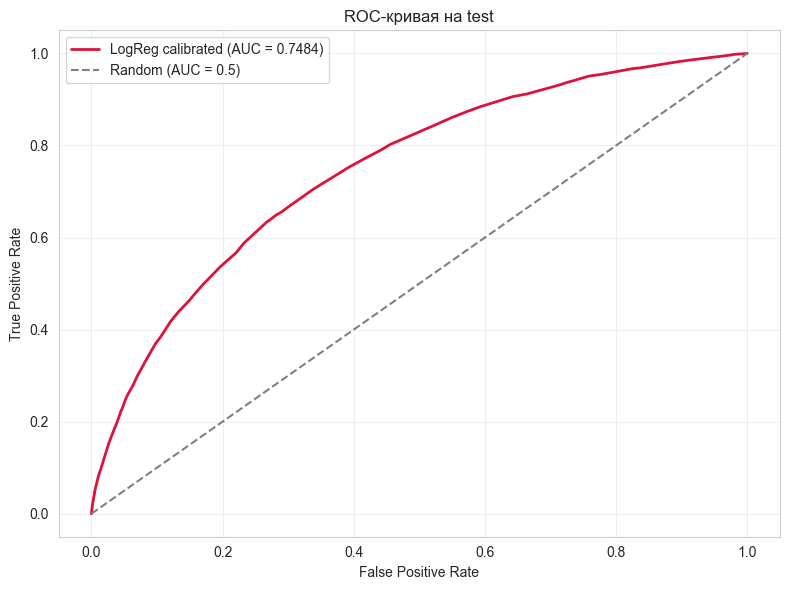

In [16]:
# 1. Калибровка (isotonic) с использованием FrozenEstimator
# Оборачиваем уже обученную модель, чтобы калибровщик не переобучал её
calibrated_model = CalibratedClassifierCV(
    estimator=FrozenEstimator(model), 
    method='isotonic'
)

# Обучаем калибровщик на train (он подстроит вероятности под реальный масштаб)
calibrated_model.fit(X_train_scaled, y_train)

y_pred_proba_cal = calibrated_model.predict_proba(X_test_scaled)[:, 1]

# 2. Сравнение метрик до/после калибровки
print("--- До калибровки ---")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"Brier:   {brier_score_loss(y_test, y_pred_proba):.4f}")

print("\n--- После калибровки ---")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_cal):.4f}")
print(f"Brier:   {brier_score_loss(y_test, y_pred_proba_cal):.4f}")

# 3. ROC-кривая
fpr, tpr, _ = roc_curve(y_test, y_pred_proba_cal)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, color='crimson', lw=2,
        label=f'LogReg calibrated (AUC = {roc_auc_score(y_test, y_pred_proba_cal):.4f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random (AUC = 0.5)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC-кривая на test')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Вывод по калибровке

- **ROC-AUC** остался неизменным (0.7485 → 0.7484) — калибровка не меняет ранжирование, только значения вероятностей.
- **Brier score** улучшился в 3 раза: **0.2026 → 0.0685**. Вероятности стали отражать реальные частоты дефолтов.
- **ROC-кривая** стабильна, площадь под кривой ~0.75 — модель уверенно отделяет дефолты от недефолтов.

Калиброванная модель пригодна для бизнес-применения: расчёт ожидаемых потерь, установка порога отсечения по PD, ценообразование с учётом риска.

## 9. Conclusions

### Результаты

Baseline-модель логистической регрессии для кредитного скоринга (Home Credit Default Risk) показала:

| Метрика | Значение | Комментарий |
|---------|----------|-------------|
| ROC-AUC | 0.7485 | Хороший уровень для LogReg без feature engineering |
| Gini | 0.4971 | >0.4 — сильный результат для скоринга |
| KS | 0.3689 | >0.3 — индустриальный стандарт «хорошей» модели |
| PR-AUC | 0.2288 | В 2.8x лучше случайного baseline (0.0807) |
| Brier (после калибровки) | 0.0685 | Вероятности откалиброваны, пригодны для бизнес-расчётов |

### Ключевые находки

1. **Сильнейшие признаки** — `EXT_SOURCE_1/2/3` (внешние скоринговые баллы), `AMT_CREDIT` (сумма кредита), `AMT_GOODS_PRICE` (стоимость товара/залога). Модель выявила их автоматически, что подтверждает корректность EDA.
2. **Категориальные признаки информативны** — образование, доход, семейное положение, пол. One-Hot дал +102 бинарные колонки.
3. **Заполнение `OCCUPATION_TYPE` категорией `'Unknown'`** оказалось правильным решением: признак `OCCUPATION_TYPE_Unknown` вошёл в топ-20 по важности — отсутствие данных о профессии коррелирует с риском.
4. **Калибровка критична** для скоринга: без неё вероятности нельзя использовать в бизнес-расчётах (Brier 0.20 vs 0.07).

### Ограничения

- Baseline LogReg не использует нелинейные взаимодействия — потенциально можно улучшить через feature engineering (агрегации из `bureau`, `previous_application`).
- Порог 0.5 — дефолтный, но в реальном скоринге его выбирают по матрице стоимости ошибок (FN vs FP).
- Модель не проверена на out-of-time валидации (нет дат в данных) — это ограничение соревнования, а не подхода.

### Что можно улучшить

1. **Feature engineering**: агрегации из `bureau.csv`, `previous_application.csv` — обычно дают +0.02–0.04 к AUC.
2. **WOE-биннинг**: стандарт скоринга, улучшает интерпретируемость и иногда качество.
3. **Тюнинг гиперпараметров**: `C` в LogReg, регуляризация L1 для отбора признаков.
4. **Scorecard**: перевод вероятностей в баллы 300–850 — финальный артефакт для продакшна.
5. **PSI-мониторинг**: стабильность модели во времени.